---
execute:
  skip: true
authors:
- name: Steffen Bollmann
doi: 10.5281/zenodo.18740155
github: https://github.com/neurodesk/neurodeskedu/blob/main/books/examples/functional_imaging/fmriprep.ipynb
edit_url: https://github.dev/neurodesk/neurodeskedu/blob/main/books/examples/functional_imaging/fmriprep.ipynb
downloads:
- url: /edu/_sources/examples/functional_imaging/fmriprep.ipynb
  title: Download source notebook
  filename: fmriprep.ipynb
  static: false
---
# fMRIprep

:::{admonition} Reviewed
:class: nd-review-badge nd-review-badge--reviewed

[review issue](<https://github.com/neurodesk/neurodeskedu-reviews/issues/12>) · [@MoniDoerig](<https://github.com/MoniDoerig>)
:::

:::{dropdown} Run this notebook
:class: nd-launch

- [Run in Australia](<https://play.neurodesk.cloud.edu.au/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/fmriprep.ipynb&branch=main>)
- [Run in Europe](<https://play-europe.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/fmriprep.ipynb&branch=main>)
- [Run in America](<https://play-america.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/fmriprep.ipynb&branch=main>)
- [Run in Global Server 1](<https://play-europe.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/fmriprep.ipynb&branch=main>)
- [Run in Global Server 2](<https://edu.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/fmriprep.ipynb&branch=main>)
:::




**Date:** 17 Oct 2024

**License:** 
<div style="margin-top: 10px;">
    <a href="https://opensource.org/licenses/MIT" target="_blank" style="color: #0066cc;">
        <i class="fas fa-balance-scale"></i> MIT License
    </a>
</div>


**Note:** If this notebook uses neuroimaging tools from Neurocontainers, those tools retain their original licenses. Please see <a href="https://neurodesk.org/overview/how-to-cite-us/" target="_blank" style="color: #0066cc;">Neurodesk citation guidelines</a> for details.

### Citation and Resources

#### Tools included in this workflow

__fMRIPrep__:
- Esteban, O., Markiewicz, C.J., Blair, R.W. et al. fMRIPrep: a robust preprocessing pipeline for functional MRI. Nat Methods 16, 111–116 (2019). [https://doi.org/10.1038/s41592-018-0235-4](https://doi.org/10.1038/s41592-018-0235-4)
  
#### Dataset
__Flanker Dataset from OpenNeuro:__
- Kelly AMC and Uddin LQ and Biswal BB and Castellanos FX and Milham MP (2018). Flanker task (event-related). [OpenNeuro Dataset ds000102](https://openneuro.org/datasets/ds000102/versions/00001)
- Kelly, A. M., Uddin, L. Q., Biswal, B. B., Castellanos, F. X., & Milham, M. P. (2008). Competition between functional brain networks mediates behavioral variability. NeuroImage, 39(1), 527–537. [https://doi.org/10.1016/j.neuroimage.2007.08.008](https://doi.org/10.1016/j.neuroimage.2007.08.008)

#### Educational resources
- [fMRIPrep documentation](https://fmriprep.org/en/stable/)

## Demonstrationg fMRIprep on Neurodesk
Preprocessing is a critical step in fMRI analysis, converting raw fMRI data into a form ready for statistical analysis. fMRIPrep is a robust, automated preprocessing pipeline that performs basic processing steps (coregistration, normalization, unwarping, noise component extraction, segmentation, skull-stripping, etc.), providing outputs that can be easily submitted to a variety of group level analyses, including task-based or resting-state fMRI, graph theory measures, and surface or volume-based statistics. It combines tools from well-known software packages including FSL, ANTs, FreeSurfer and AFNI, and generates quality reports that allow users to easily identify outliers

In this notebook, we demonstrate how to run fMRIPrep on a BIDS-formatted dataset and explore examples of the outputs it generates.

![fMRIPrep workflow](https://github.com/oesteban/fmriprep/raw/f4c7a9804be26c912b24ef4dccba54bdd72fa1fd/docs/_static/fmriprep-21.0.0.svg)

### Load fMRIPrep and request FreeSurfer license

In [1]:
# load fmriprep
import module
import os
await module.load('fmriprep/24.1.0')
await module.list()

['fmriprep/24.1.0']

In [2]:
# Request a freesurfer license and store it in your homedirectory. This is just an exampe - please replace with your license id:
!echo "Steffen.Bollmann@cai.uq.edu.au" > ~/.license
!echo "21029" >> ~/.license
!echo "*Cqyn12sqTCxo" >> ~/.license
!echo "FSxgcvGkNR59Y" >> ~/.license

### Download Data

In [3]:
%%bash
set -euo pipefail
# Retry transient network failures, then fail the cell instead of continuing without data.
retry() { for i in 1 2 3 4 5; do "$@" && return 0; echo "Attempt $i failed: $*" >&2; [ "$i" -lt 5 ] && sleep $((i * 15)); done; return 1; }
[ -d ds000102 ] || retry datalad install https://github.com/OpenNeuroDatasets/ds000102.git
cd ds000102 && retry datalad get sub-08

[INFO] Attempting a clone into /home/jovyan/workspace/books/examples/functional_imaging/ds000102 
[INFO] Attempting to clone from https://github.com/OpenNeuroDatasets/ds000102.git to /home/jovyan/workspace/books/examples/functional_imaging/ds000102 
[INFO] Start enumerating objects 
[INFO] Start counting objects 
[INFO] Start compressing objects 
[INFO] Start receiving objects 
[INFO] Start resolving deltas 
[INFO] Completed clone attempts for Dataset(/home/jovyan/workspace/books/examples/functional_imaging/ds000102) 
[INFO] Remote origin not usable by git-annex; setting annex-ignore 
[INFO] https://github.com/OpenNeuroDatasets/ds000102.git/config download failed: Not Found 
[INFO] access to 1 dataset sibling s3-PRIVATE not auto-enabled, enable with:
| 		datalad siblings -d "/home/jovyan/workspace/books/examples/functional_imaging/ds000102" enable -s s3-PRIVATE 


install(ok): /home/jovyan/workspace/books/examples/functional_imaging/ds000102 (dataset)
get(ok): sub-08/anat/sub-08_T1w.nii.gz (file) [from s3-PUBLIC...]
get(ok): sub-08/func/sub-08_task-flanker_run-1_bold.nii.gz (file) [from s3-PUBLIC...]
get(ok): sub-08/func/sub-08_task-flanker_run-2_bold.nii.gz (file) [from s3-PUBLIC...]
get(ok): sub-08 (directory)
action summary:
  get (ok: 4)


### Run fMRIPrep

In [4]:
%%bash
# set up environment variables
export SUBJECTS_DIR=$PWD/fmriprep-freesurfer-dir
export APPTAINERENV_SUBJECTS_DIR=$SUBJECTS_DIR
export ITK_GLOBAL_DEFAULT_NUMBER_OF_THREADS=2 
export MPLCONFIGDIR=~/matplotlib-mpldir 

# create subjects directory
mkdir -p $SUBJECTS_DIR

# run fmriprep
fmriprep ds000102/ fmriprep-output participant \
--fs-license-file ~/.license \
--output-spaces T1w MNI152NLin2009cAsym fsaverage fsnative \
--participant-label 08 \
--nprocs $ITK_GLOBAL_DEFAULT_NUMBER_OF_THREADS \
--mem 10000 \
--skip_bids_validation \
--fs-subjects-dir $SUBJECTS_DIR \
-v


2026-10-08 16:38:38,297 [ WARNING] WARNING: SOCKS support in urllib3 requires the installation of optional dependencies: specifically, PySocks.  For more information, see https://urllib3.readthedocs.io/en/latest/advanced-usage.html#socks-proxies
You are using fMRIPrep-24.1.0, and a newer version of fMRIPrep is available: 25.2.6.
Please check out our documentation about how and when to upgrade:
https://fmriprep.readthedocs.io/en/latest/faq.html#upgrading
2026-10-08 16:38:43,150 [    INFO] Telemetry system to collect crashes and errors is enabled - thanks for your feedback!. Use option ``--notrack`` to opt out.
2026-10-08 16:38:44,237 [ WARNING] WARNING: `sentry_sdk.Hub` is deprecated and will be removed in a future major release. Please consult our 1.x to 2.x migration guide for details on how to migrate `Hub` usage to the new API: https://docs.sentry.io/platforms/python/migration/1.x-to-2.x
2026-10-08 16:38:51,017 [ WARNING] WARNING: sentry_sdk.configure_scope is deprecated and will be

261008-16:39:56,9 nipype.workflow IMPORTANT:
	 Running fMRIPrep version 24.1.0

         License NOTICE ##################################################
         fMRIPrep 24.1.0
         Copyright The NiPreps Developers.
         
         This product includes software developed by
         the NiPreps Community (https://nipreps.org/).
         
         Portions of this software were developed at the Department of
         Psychology at Stanford University, Stanford, CA, US.
         
         This software is also distributed as a Docker container image.
         The bootstrapping file for the image ("Dockerfile") is licensed
         under the MIT License.
         
         This software may be distributed through an add-on package called
         "Docker Wrapper" that is under the BSD 3-clause License.
         #################################################################
261008-16:39:56,36 nipype.workflow IMPORTANT:
	 Building fMRIPrep's workflow:
           * BIDS dataset

## fMRIprep Results

The full result report is in fmriprep-output/sub-08.html and you can open this webpage in Jupyterlab or in the browser. Here a few items from the report as an example and for a quick check:

### T1 and brain mask
Template T1-weighted image (if several T1w images were found), with contours delineating the detected brain mask and brain tissue segmentations.

In [5]:
from IPython.core.display import SVG
SVG(filename='fmriprep-output/sub-08/figures/sub-08_dseg.svg')

### Surfaces
Surfaces (white and pial) reconstructed with FreeSurfer (recon-all) overlaid on the participant's T1w template.

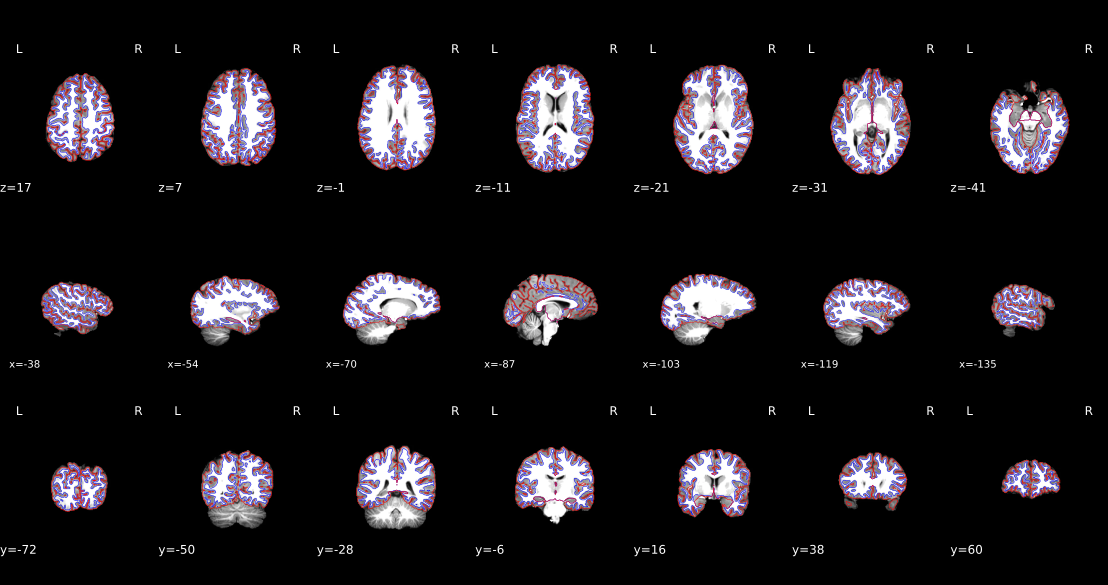

In [6]:
SVG(filename='fmriprep-output/sub-08/figures/sub-08_desc-reconall_T1w.svg')

### EPI-space to T1-space

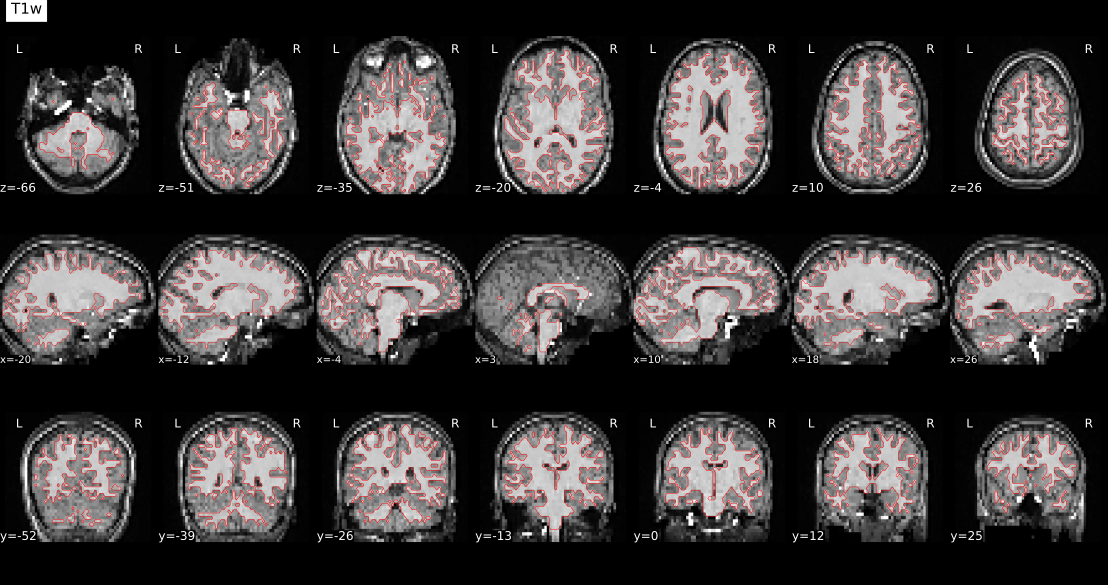

In [7]:
SVG(filename='fmriprep-output/sub-08/figures/sub-08_task-flanker_run-1_desc-coreg_bold.svg')

## Brain mask and (anatomical/temporal) CompCor ROIs
Brain mask calculated on the BOLD signal (red contour), along with the regions of interest (ROIs) used for the estimation of physiological and movement confounding components that can be then used as nuisance regressors in analysis.
The anatomical CompCor ROI (magenta contour) is a mask combining CSF and WM (white-matter), where voxels containing a minimal partial volume of GM have been removed.
The temporal CompCor ROI (blue contour) contains the top 2% most variable voxels within the brain mask.
The brain edge (or crown) ROI (green contour) picks signals outside but close to the brain, which are decomposed into 24 principal components.

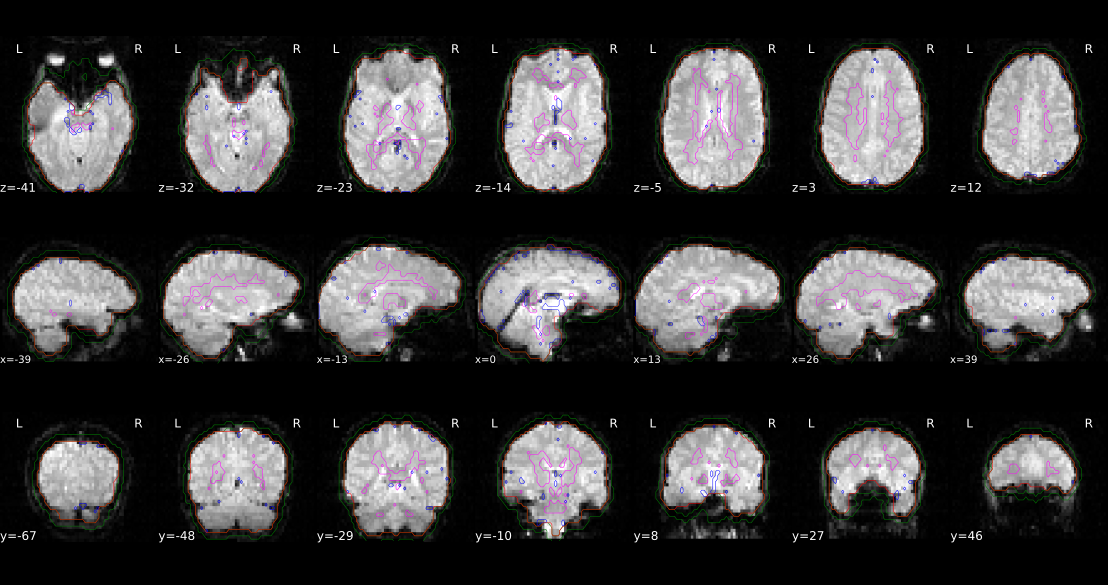

In [8]:
SVG(filename='fmriprep-output/sub-08/figures/sub-08_task-flanker_run-1_desc-rois_bold.svg')

### Bold Summary
Summary statistics are plotted, which may reveal trends or artifacts in the BOLD data. Global signals calculated within the whole-brain (GS), within the white-matter (WM) and within cerebro-spinal fluid (CSF) show the mean BOLD signal in their corresponding masks. DVARS and FD show the standardized DVARS and framewise-displacement measures for each time point.
A carpet plot shows the time series for all voxels within the brain mask, or if --cifti-output was enabled, all grayordinates. Voxels are grouped into cortical (dark/light blue), and subcortical (orange) gray matter, cerebellum (green) and white matter and CSF (red), indicated by the color map on the left-hand side.

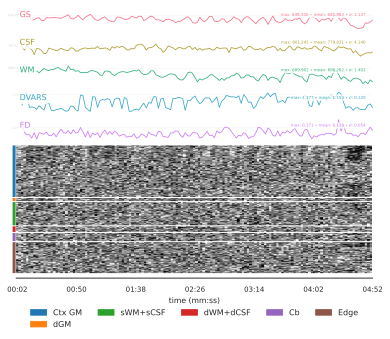

In [9]:
SVG(filename='fmriprep-output/sub-08/figures/sub-08_task-flanker_run-1_desc-carpetplot_bold.svg')

#### Dependencies in Jupyter/Python
- Using the package [watermark](https://github.com/rasbt/watermark) to document system environment and software versions used in this notebook, alongside the Neurodesktop version extracted from the `JUPYTER_IMAGE` or `NEURODESKTOP_VERSION` environment variables.

In [10]:
import os

%load_ext watermark

%watermark
%watermark --iversions

neurodesktop_version = (
    os.environ.get('JUPYTER_IMAGE', '').split(':')[-1] or
    os.environ.get('NEURODESKTOP_VERSION', 'unknown')
)

print(f"Neurodesktop version: {neurodesktop_version}")

Last updated: 2026-10-08T23:32:44.408963+00:00

Python implementation: CPython
Python version       : 3.13.15
IPython version      : 9.17.1

Compiler    : GCC 15.3.0
OS          : Linux
Release     : 6.8.0-111-generic
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit

IPython: 9.17.1

Neurodesktop version: 2026-10-05
